# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [1]:
# %pip install imbalanced-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style("darkgrid")

from typing import Final
RANDOM_STATE: Final[int] = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.


Обозначим через $\widetilde X=[\mathbf 1,X]$ матрицу с фиктивным признаком, $z=\widetilde Xw$, $p=\sigma(z)$ и $n$ - число объектов.

Для одного объекта $\ell_i = -y_i \log p_i-(1-y_i) \log(1-p_i)$:

$$
\frac{\partial \ell_i}{\partial p_i}
= -\frac{y_i}{p_i} + \frac{1 - y_i}{1 - p_i}
= \frac{p_i - y_i}{p_i(1 - p_i)}, \qquad \frac{\partial p_i}{\partial z_i}
= p_i(1 - p_i),\qquad \frac{\partial z_i}{\partial w}
= \widetilde x_i.
$$

Так как $p_i = \sigma(z)$, а производная для сигмоиды уже была рассмотрена в рамках курса - вывод опущен.

Производная сложной функции (перемножаем значения выше): $\nabla_w \ell_i = (p_i - y_i) \widetilde x_i$.

Подставив назад в сумму и записав в матричном виде получаем:

$$
\boxed{\nabla Q(w) = \frac1n\widetilde X^\top(\sigma(\widetilde Xw) - y)}.
$$

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type="full"` (1 балл);
- **стохастического градиентного спуска** – `gd_type="stochastic"`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [3]:
from typing import Literal

class LogReg(BaseEstimator, ClassifierMixin):
    stop_reason_: Literal["max_iter", "tolerance"]

    def __init__(
            self,
            gd_type: Literal["full", "stochastic"]="full",
            tolerance=1e-4,
            max_iter=1000,
            w0: np.ndarray | None=None,
            eta=1e-2,
            batch_size=32,
            random_state=RANDOM_STATE
        ):
        """Параметры спуска; w0[0] соответствует свободному члену."""
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        """Обучение на X размера (N, d) и бинарных метках y размера (N,)."""
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        self.classes_ = np.array([0, 1])
        self.n_features_in_ = X.shape[1]
        self.loss_history = []

        X = np.column_stack((np.ones(X.shape[0]), X))
        rng = np.random.default_rng(self.random_state)

        self.w = (
            np.zeros(X.shape[1]) if self.w0 is None
            else np.array(self.w0, dtype=float, copy=True)
        )
        if self.w.shape != (X.shape[1],) or not np.isfinite(self.w).all():
            raise ValueError("w0 должен быть конечным вектором размера d + 1")

        self.stop_reason_ = "max_iter"
        for iteration in range(self.max_iter):
            self.loss_history.append(self.calc_loss(X, y))

            if self.gd_type == "stochastic":
                indices = rng.choice(
                    X.shape[0], size=min(self.batch_size, X.shape[0]), replace=False
                )
                gradient = self.calc_gradient(X[indices], y[indices])
            else:
                gradient = self.calc_gradient(X, y)

            step = -self.eta * gradient
            self.w = self.w + step
            self.n_iter_ = iteration + 1

            if np.linalg.norm(step) < self.tolerance:
                self.stop_reason_ = "tolerance"
                break

        # Это значение уже ПОСЛЕ последнего шага, в отличие от loss_history[-1].
        self.final_loss_ = self.calc_loss(X, y)
        return self

    def sigmoid(self, z):
        z = np.asarray(z, dtype=float)
        return np.exp(-np.logaddexp(0, -z))

    def predict_proba(self, X):
        """Возвращает вероятности классов 0 и 1, массив размера (N, 2)."""
        if getattr(self, "w", None) is None:
            raise Exception("Модель ещё не обучена")
        
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] + 1 != self.w.size:
            raise ValueError("Число признаков должно совпадать с обучением")
        
        X = np.column_stack((np.ones(X.shape[0]), X))
        p = self.sigmoid(X @ self.w)
        return np.column_stack((1 - p, p))

    def predict(self, X, threshold=0.5):
        """Возвращает метки 0/1 по заданному порогу вероятности класса 1."""
        if getattr(self, "w", None) is None:
            raise Exception("Модель ещё не обучена")
        if not 0 <= threshold <= 1:
            raise ValueError("Порог должен лежать в [0, 1]")
        
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        """Градиент среднего log-loss; X уже содержит столбец единиц."""
        return X.T @ (self.sigmoid(X @ self.w) - y) / X.shape[0]

    def calc_loss(self, X, y):
        """Средний log-loss через логиты; X уже содержит столбец единиц."""
        z = X @ self.w
        return float(np.mean(np.logaddexp(0, (1 - 2 * y) * z)))

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [4]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f"max |analytic - numeric| = {err:.2e}")
assert err < 1e-5, "Градиент не совпадает с численным — проверьте calc_gradient и calc_loss"

max |analytic - numeric| = 1.17e-10


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type="full")` и `LogReg(gd_type="stochastic")` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

,Итерации,Причина остановки,Финальная потеря
Метод,,,
GD,1000,max_iter,0.512435
SGD,1000,max_iter,0.512909


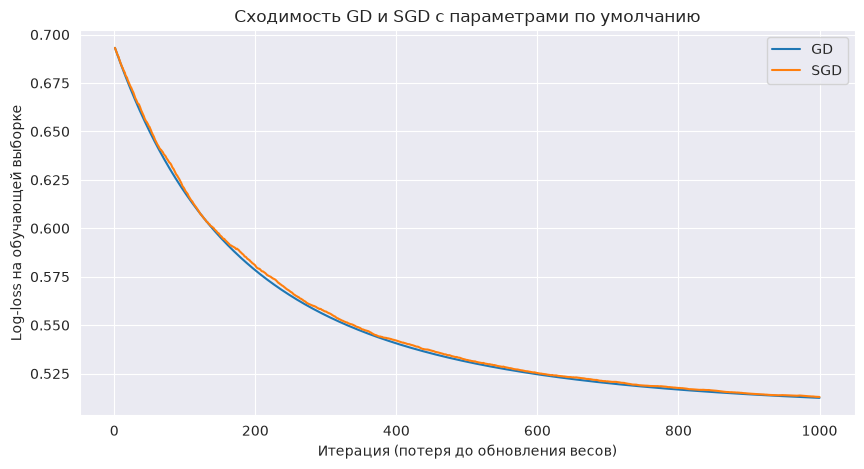

In [6]:
def plot_loss_histories(models, title, log_x=False, ax=None):
    """Общий график сходимости: словарь «подпись: обученная модель»."""
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 5))

    for label, model in models.items():
        ax.plot(
            np.arange(1, len(model.loss_history) + 1),
            model.loss_history,
            label=label
        )
    if log_x:
        ax.set_xscale("log")
    ax.set(
        xlabel="Итерация (потеря до обновления весов)",
        ylabel="Log-loss на обучающей выборке",
        title=title
    )
    ax.legend()
    return ax


models_default = {
    "GD": LogReg(gd_type="full").fit(X_train, y_train),
    "SGD": LogReg(gd_type="stochastic").fit(X_train, y_train),
}
convergence_table = pd.DataFrame([
    {
        "Метод": name,
        "Итерации": model.n_iter_,
        "Причина остановки": model.stop_reason_,
        "Финальная потеря": model.final_loss_
    }
    for name, model in models_default.items()
]).set_index("Метод")
display(convergence_table)

plot_loss_histories(models_default, "Сходимость GD и SGD с параметрами по умолчанию")
plt.show()

   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?


1. При `eta=0.01` обе модели достигают лимита `max_iter=1000`
2.  При постоянном шаге шум оценки градиента сохраняется даже около минимума, поэтому норме обновления трудно устойчиво стать меньше `tolerance`. Случайное выполнение критерия у SGD само по себе не гарантирует близости к минимуму.
3. У SGD, в отличие от GD кривая не гладкая, наблюдаются скачки / отклонения, вызванные взятием случайной подвыборки
4. GD использует все объекты train за шаг, а SGD - 32. Однако по условию `loss_history` в обоих случаях вычисляется
на всех объектах на каждом шаге.

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

,Финальная потеря,Итерации,Причина остановки
eta,,,
0.001,0.618087,1000,max_iter
0.010,0.512435,1000,max_iter
0.100,0.505762,465,tolerance
1.000,0.505757,70,tolerance
10.000,0.901345,1000,max_iter


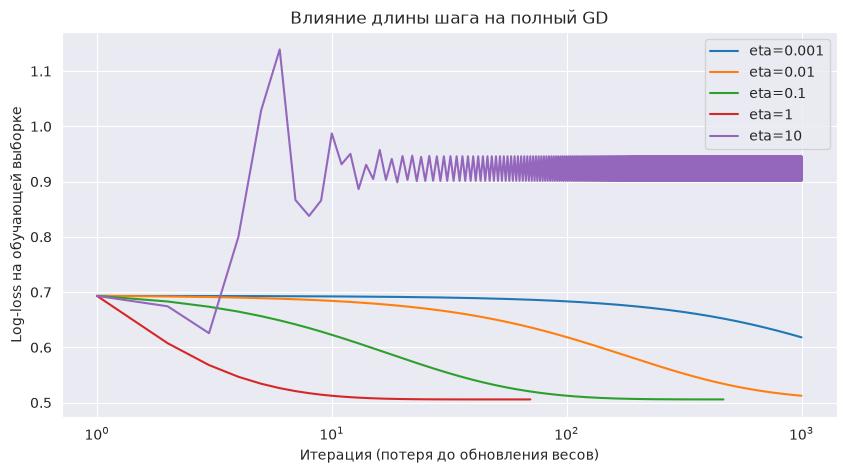

In [7]:
eta_grid = [1e-3, 1e-2, 1e-1, 1, 10]
models_eta = {
    f"eta={eta:g}": LogReg(gd_type="full", eta=eta).fit(X_train, y_train)
    for eta in eta_grid
}

eta_table = pd.DataFrame([
    {
        "eta": model.eta,
        "Финальная потеря": model.final_loss_,
        "Итерации": model.n_iter_,
        "Причина остановки": model.stop_reason_
    }
    for model in models_eta.values()
]).set_index("eta")

display(eta_table)
plot_loss_histories(models_eta, "Влияние длины шага на полный GD", log_x=True)
plt.show()

Малые шаги `0.001` и `0.01` приводят к медленному уменьшению потерь:
за 1000 итераций они ещё не достигают минимума. Шаги `0.1` и `1` ускоряют сходимость.

Шаг `eta=10` слишком большой: наблюдаются колебания и существенно бОльшая финальная потеря.
Смотря на график, можно сделать вывод, что алгоритм "застрял" и не сойдется к минимуму.
Конкретные значения и причины остановки указаны в таблице.

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

,Accuracy,ROC-AUC
Модель,,
GD,0.7820,0.838787
SGD,0.7825,0.838115
sklearn,0.7765,0.838676


,GD,sklearn,GD - sklearn
w0 (свободный член),-0.002114,-0.021880,0.019765
w1,0.006076,0.002741,0.003335
w2,0.006963,0.009039,-0.002077
w3,-0.547170,-0.722690,0.175520
w4,-0.144536,-0.262335,0.117799
w5,0.012487,0.016588,-0.004102
w6,-0.006325,-0.011488,0.005163
w7,0.000814,0.005587,-0.004773
w8,0.039084,0.057188,-0.018104
w9,-0.002425,-0.001239,-0.001185


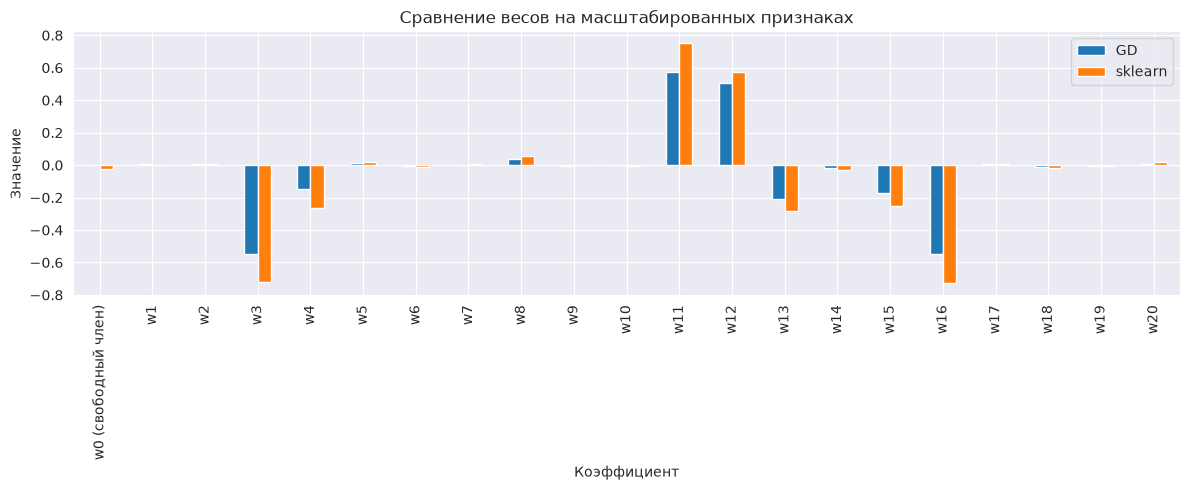

GD: 191 шагов, остановка: tolerance
Норма градиента GD: 8.94e-10
Максимальная разность весов без регуляризации: 8.81e-09
Максимальная разность логитов на train: 4.35e-08


In [8]:
sklearn_model = LogisticRegression().fit(X_train, y_train)
comparison_models = {**models_default, "sklearn": sklearn_model}
quality_table = pd.DataFrame([
    {
        "Модель": name,
        "Accuracy": metrics.accuracy_score(y_test, model.predict(X_test)),
        "ROC-AUC": metrics.roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    }
    for name, model in comparison_models.items()
]).set_index("Модель")
display(quality_table)

sklearn_weights = np.r_[sklearn_model.intercept_, sklearn_model.coef_.ravel()]
weight_table = pd.DataFrame(
    {
        "GD": models_default["GD"].w,
        "sklearn": sklearn_weights,
        "GD - sklearn": models_default["GD"].w - sklearn_weights,
    },
    index=["w0 (свободный член)"] + [
        f"w{j}"
        for j in range(1, X_train.shape[1] + 1)
    ]
)
display(weight_table)

weight_table[["GD", "sklearn"]].plot.bar(figsize=(12, 5))
plt.title("Сравнение весов на масштабированных признаках")
plt.xlabel("Коэффициент")
plt.ylabel("Значение")
plt.tight_layout()
plt.show()


import sklearn
from packaging.version import Version
assert Version(sklearn.__version__) >= Version("1.8"), "C=np.inf работает для версий >= 1.8. Пожалуйста, обновите scikit-learn"

sklearn_unregularized = LogisticRegression(
    C=np.inf, tol=1e-10, max_iter=10000
).fit(X_train, y_train)

gd_converged = LogReg(eta=1, tolerance=1e-9, max_iter=20000).fit(X_train, y_train)
X_train_bias = np.column_stack((np.ones(X_train.shape[0]), X_train))
w_unregularized = np.r_[sklearn_unregularized.intercept_, sklearn_unregularized.coef_.ravel()]
train_logits_difference = X_train_bias @ (gd_converged.w - w_unregularized)

print(f"GD: {gd_converged.n_iter_} шагов, остановка: {gd_converged.stop_reason_}")
print(f"Норма градиента GD: {np.linalg.norm(gd_converged.calc_gradient(X_train_bias, y_train)):.2e}")
print(f"Максимальная разность весов без регуляризации: {np.max(np.abs(gd_converged.w - w_unregularized)):.2e}")
print(f"Максимальная разность логитов на train: {np.max(np.abs(train_logits_difference)):.2e}")

Метрики моделей близки, но не совпадают в точности.
Веса GD с параметрами по умолчанию отличаются от весов sklearn: 1000 шагов при `eta=0.01` недостаточно для точной сходимости; SGD дополнительно испытывает шум батчей.

По [документации LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), sklearn по умолчанию применяет L2-регуляризацию с `C=1` и алгоритм `lbfgs`. В нашей модели штрафа нет.

Чтобы решать ту же задачу, предлагается отключить регуляризацию: `C=np.inf` (начиная с `scikit-learn` 1.8, поэтому в коде assert на версию).
Также увеличиваем `max_iter` и уменьшаем допуск обеих моделей; критерии останова
у GD и L-BFGS различаются.

В дополнительной проверке без регуляризации GD остановился за 191 шаг: норма градиента $8.94\cdot10^{-10}$, максимальная разность весов $8.81\cdot10^{-9}$, а логитов на train - $4.35\cdot10^{-8}$.

Вывод: при достаточной точности обе реализации решают одну задачу.


## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [9]:
df = pd.read_csv('https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_3/Data/wine_quality.csv')

print('Data shape:', df.shape)
df.head()

Data shape: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [10]:
df_raw = df.copy()
missing_counts = df_raw.isna().sum()
duplicate_count = int(df_raw.duplicated().sum())
print(f"Исходный размер: {df_raw.shape}")
print(f"Полных дубликатов сверх первого экземпляра: {duplicate_count}")
display(missing_counts.to_frame("Пропуски"))

# Удаляем полные дубликаты до разбиения, чтобы одинаковые строки не попали
# одновременно в обучение и тест. Признаки и target входят в проверку.
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Размер после удаления дубликатов: {df.shape}")
display(df.head())

Исходный размер: (6497, 13)
Полных дубликатов сверх первого экземпляра: 1177


,Пропуски
fixed_acidity,0
volatile_acidity,0
citric_acid,0
residual_sugar,0
chlorides,0
free_sulfur_dioxide,0
total_sulfur_dioxide,0
density,0
pH,0
sulphates,0


Размер после удаления дубликатов: (5320, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,1,0


In [11]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (3724, 12)  Test: (1596, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [12]:
print(f"Всего пропущенных значений: {missing_counts.sum()}")
print(f"Удалено дубликатов: {duplicate_count}; осталось: {df.duplicated().sum()}")
prevalence_table = pd.DataFrame({
    "Размер": [len(y_train), len(y_test)],
    "Доля класса 1": [y_train.mean(), y_test.mean()],
}, index=["train", "test"])
display(prevalence_table)

wine_model = make_pipeline(StandardScaler(), LogisticRegression())
wine_model.fit(X_train, y_train)

y_pred_wine = wine_model.predict(X_test)
p_wine = wine_model.predict_proba(X_test)[:, 1]
accuracy_table = pd.DataFrame({
    "Accuracy": [
        metrics.accuracy_score(y_test, np.zeros(len(y_test), dtype=int)),
        metrics.accuracy_score(y_test, y_pred_wine),
    ]
}, index=["Всегда класс 0", "Логистическая регрессия"])
display(accuracy_table)

train_rows = pd.MultiIndex.from_frame(df.loc[X_train.index])
test_rows = pd.MultiIndex.from_frame(df.loc[X_test.index])
assert train_rows.intersection(test_rows).empty, "train и test пересекаются"

Всего пропущенных значений: 0
Удалено дубликатов: 1177; осталось: 0


,Размер,Доля класса 1
train,3724,0.189581
test,1596,0.189850


,Accuracy
Всегда класс 0,0.810150
Логистическая регрессия,0.815163


В исходных данных 6497 строк, пропусков нет; удалено 1177 дубликатов, осталось 5320 строк.
Совпадение измерений не доказывает, что это одно и то же вино. В описании датасета сказано, что некоторые признаки были скрыты. Точность также урезана, так что эти данные вполне могут быть независимыми и не представлять дубликаты, но здесь стоит отметить "утечку данных". Записи, являющиеся по предоставенным признакам полными копиями, могут попасть как в train, так и в test, чир способно исказить модель.

`stratify=y` позволяет примерно сохраняет долю хороших вин в train и test (аналогично изначальному датасету).

Accuracy лог рег немного выше чем у модели, предсказывающей наиболее частый класс (на ~0.005).
Accuracy плохо подходит для этой задачи, так как распределение между классами не одинаково.
Доминация класса 0 позволяет держать метрику высоко, всегда предсказывая его (так как вхождений с ним заметно больше)

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

,TN,FP,FN,TP
0,1209,84,211,92


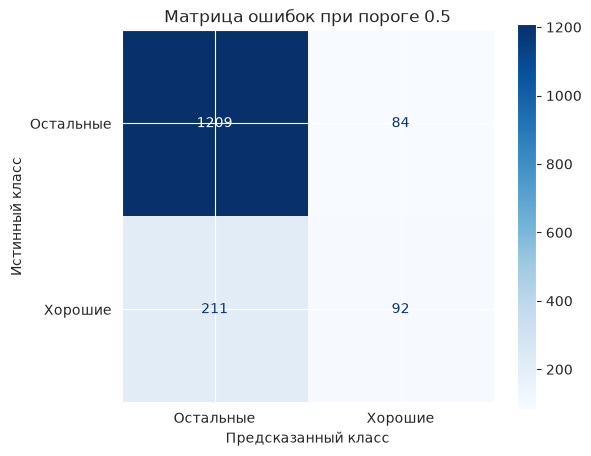

In [13]:
y_true_wine = np.asarray(y_test)
TP: int = int(np.sum((y_true_wine == 1) & (y_pred_wine == 1)))
TN: int = int(np.sum((y_true_wine == 0) & (y_pred_wine == 0)))
FP: int = int(np.sum((y_true_wine == 0) & (y_pred_wine == 1)))
FN: int = int(np.sum((y_true_wine == 1) & (y_pred_wine == 0)))

cm_manual = np.array([[TN, FP], [FN, TP]])
assert cm_manual.sum() == len(y_test)
display(pd.DataFrame({"TN": [TN], "FP": [FP], "FN": [FN], "TP": [TP]}))

cm_sklearn = metrics.confusion_matrix(y_test, y_pred_wine, labels=[0, 1])
# Проверка ручных подсчетов
np.testing.assert_array_equal(cm_manual, cm_sklearn)

_, ax = plt.subplots(figsize=(6, 5))
metrics.ConfusionMatrixDisplay(
    confusion_matrix=cm_manual,
    display_labels=["Остальные", "Хорошие"],
).plot(ax=ax, cmap="Blues")
ax.set(
    xlabel="Предсказанный класс",
    ylabel="Истинный класс",
    title="Матрица ошибок при пороге 0.5"
)
plt.show()

- FP - посредственное вино ошибочно попало в подборку; клиент может
разочароваться.
- FN - хорошее вино пропущено, поэтому подборка стала скуднее.

Получено TN=1209, FP=84, FN=211, TP=92. Пропуски хороших вин (FN) встречаются чаще ошибочных рекомендаций (FP): 211 против 84.


### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [14]:
def safe_ratio(numerator: int | float, denominator: int | float) -> float:
    """При нулевом знаменателе принимаем значение метрики равным нулю."""
    return numerator / denominator if denominator else 0.0


precision_manual: float = safe_ratio(TP, TP + FP)
recall_manual: float = safe_ratio(TP, TP + FN)


def fbeta_from_precision_recall(precision, recall, beta=1):
    return safe_ratio(
        (1 + beta**2) * precision * recall,
        beta**2 * precision + recall,
    )


manual_values = [precision_manual, recall_manual] + [
    fbeta_from_precision_recall(precision_manual, recall_manual, beta) for beta in [1, 0.5, 2]
]
sklearn_values = [
    metrics.precision_score(y_test, y_pred_wine, zero_division=0),
    metrics.recall_score(y_test, y_pred_wine, zero_division=0),
] + [
    metrics.fbeta_score(y_test, y_pred_wine, beta=beta, zero_division=0)
    for beta in [1, 0.5, 2]
]
manual_metrics_table = pd.DataFrame({
    "По формулам": manual_values,
    "sklearn": sklearn_values,
}, index=["Precision", "Recall", "F1", "F0.5", "F2"])

np.testing.assert_allclose(
    np.asarray(manual_values, dtype=np.float64),
    np.asarray(sklearn_values, dtype=np.float64),
)
display(manual_metrics_table)

,По формулам,sklearn
Precision,0.522727,0.522727
Recall,0.303630,0.303630
F1,0.384134,0.384134
F0.5,0.456802,0.456802
F2,0.331412,0.331412


Интерпретировать значение $\beta$ будет проще, если переписать F метрику как среднее гармоническое:

$$
\frac{1}{F_\beta}
= \frac{1}{1 + \beta^2} \cdot \frac{1}{P} + \frac{\beta^2}{1 + \beta^2} \cdot \frac{1}{R} 
$$

- $F_{0.5}$ сильнее учитывает precision: подходит, когда клиентам
особенно неприятны посредственные вина в подборке.
- $F_1$ симметрично учитывает precision и recall.
- $F_2$ сильнее учитывает recall: подходит сервису с приоритетом широкой подборки хороших вин.


### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type="full")` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

GD: 4876 итераций, потеря на train=0.365807


,ROC-AUC,PR-AUC (AP)
sklearn,0.820876,0.484766
Рукописный GD,0.820562,0.483769


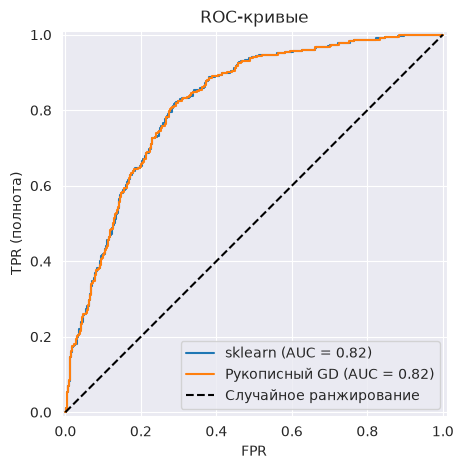

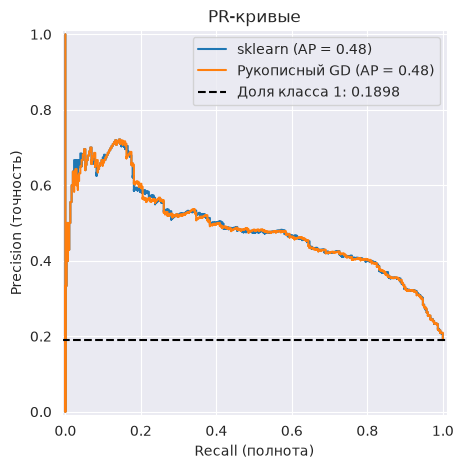

,ROC-AUC
p,0.820876
10p,0.820876
p^3,0.820876
log(p / (1 - p)),0.820876
-p,0.179124
Метки при пороге 0.5,0.619333


In [15]:
wine_scaler = StandardScaler()
X_train_wine_scaled = wine_scaler.fit_transform(X_train)
X_test_wine_scaled = wine_scaler.transform(X_test)

wine_gd = LogReg(eta=1, tolerance=1e-7, max_iter=10000).fit(X_train_wine_scaled, y_train)
assert wine_gd.stop_reason_ == "tolerance", "GD не сошёлся"
print(f"GD: {wine_gd.n_iter_} итераций, потеря на train={wine_gd.final_loss_:.6f}")

y_roc = np.asarray(y_test, dtype=np.int64)
wine_scores = {
    "sklearn": np.asarray(p_wine, dtype=np.float64),
    "Рукописный GD": np.asarray(wine_gd.predict_proba(X_test_wine_scaled)[:, 1], dtype=np.float64),
}
ranking_table = pd.DataFrame({
    name: {
        "ROC-AUC": float(metrics.roc_auc_score(y_roc, score)),
        "PR-AUC (AP)": float(metrics.average_precision_score(y_roc, score)),
    }
    for name, score in wine_scores.items()
}).T
display(ranking_table)

_, ax_roc = plt.subplots(figsize=(7, 5))
_, ax_pr = plt.subplots(figsize=(7, 5))
for name, score in wine_scores.items():
    metrics.RocCurveDisplay.from_predictions(y_roc, score, name=name, ax=ax_roc)
    metrics.PrecisionRecallDisplay.from_predictions(y_roc, score, name=name, ax=ax_pr)
ax_roc.plot([0, 1], [0, 1], "k--", label="Случайное ранжирование")
ax_pr.axhline(
    float(y_roc.mean()),
    color="black",
    linestyle="--",
    label=f"Доля класса 1: {y_roc.mean():.4f}"
)
ax_roc.set(title="ROC-кривые", xlabel="FPR", ylabel="TPR (полнота)")
ax_pr.set(title="PR-кривые", xlabel="Recall (полнота)", ylabel="Precision (точность)")
ax_roc.legend()
ax_pr.legend()
plt.show()

p = wine_scores["sklearn"]
p_safe = np.clip(p, 1e-15, 1 - 1e-15)
transformed_scores = {
    "p": p,
    "10p": 10 * p,
    "p^3": p**3,
    "log(p / (1 - p))": np.log(p_safe / (1 - p_safe)),
    "-p": -p,
    "Метки при пороге 0.5": (p >= 0.5).astype(np.float64),
}
auc_transformations = pd.DataFrame({
    "ROC-AUC": {
        name: float(metrics.roc_auc_score(y_roc, score))
        for name, score in transformed_scores.items()
    }
})
display(auc_transformations)


Строго возрастающие преобразования $10p$, $p^3$ и $\log(p/(1-p))$ сохраняют порядок, поэтому ROC-AUC не меняется. Оценка $-p$ обращает порядок: $\mathrm{AUC}(-p)=1-\mathrm{AUC}(p)$.

- На полученном тестовом разбиении модели показывают близкое качество ранжирования. sklearn несущественно вырывается вперед, однако по одному разбиению нельзя судить о статистической значимости этих различий

- Базовый уровень precision случайного ранжирования равен $\pi=P(y=1)$, а не 0.5. Cреди случайно выбранных вин доля хороших такая же, как в выборке.

Если подать метки классов, sklearn посчитает ROC-AUC, но смысл метрики изменится:
ROC кривая будет содержать всего три точки (0, 0), (FPR, TPR), (1, 1).
Площадь таким образом составит $\frac{1 + TPR - FPR}{2}$, а это в свою очередь эквивалентно сбалансированной точности

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

,Порог,Precision,Recall,F1
t_F1,0.286550,0.470339,0.630682,0.538835
t_R,0.236359,0.426117,0.704545,0.531049


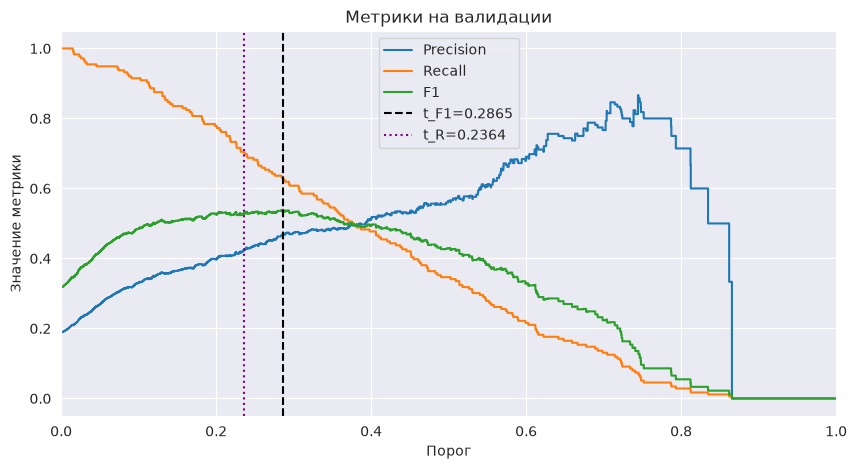

,Порог,Precision,Recall,F1
Вариант,,,,
По умолчанию,0.500000,0.522727,0.303630,0.384134
t_F1,0.286550,0.457421,0.620462,0.526611
t_R,0.236359,0.421260,0.706271,0.527744


Условие recall ≥ 0.7 на тесте для t_R: True


In [16]:
from numpy.typing import ArrayLike


def threshold_metrics(
        y_true: ArrayLike,
        probabilities: ArrayLike,
        threshold: float = 0.5
) -> dict[str, float]:
    predicted = np.asarray(probabilities) >= threshold
    return {
        "Precision": float(metrics.precision_score(y_true, predicted, zero_division=0)),
        "Recall": float(metrics.recall_score(y_true, predicted, zero_division=0)),
        "F1": float(metrics.f1_score(y_true, predicted, zero_division=0)),
    }


X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train, y_train,
    test_size=0.25,
    stratify=y_train,
    random_state=RANDOM_STATE
)
validation_model = make_pipeline(StandardScaler(), LogisticRegression())
validation_model.fit(X_subtrain, y_subtrain)
p_val = np.asarray(validation_model.predict_proba(X_val), dtype=np.float64)[:, 1]

# Проверяем все пороги, на которых меняются прогнозы, и границы [0, 1].
threshold_curve = pd.DataFrame([
    {"Порог": float(t), **threshold_metrics(y_val, p_val, float(t))}
    for t in np.unique(np.r_[0.0, p_val, 1.0])
])
# При равенстве F1 выбираем больший порог. При равенстве precision - больший recall, затем больший порог.
best_f1 = threshold_curve.sort_values(["F1", "Порог"]).iloc[-1]
best_recall = threshold_curve.loc[threshold_curve["Recall"] >= 0.7].sort_values(
    ["Precision", "Recall", "Порог"]
).iloc[-1]

t_F1 = float(best_f1["Порог"])
t_R = float(best_recall["Порог"])
display(pd.DataFrame([best_f1, best_recall], index=["t_F1", "t_R"]))

ax = threshold_curve.plot(
    x="Порог", y=["Precision", "Recall", "F1"],
    drawstyle="steps-pre", figsize=(10, 5)
)
ax.axvline(t_F1, color="black", linestyle="--", label=f"t_F1={t_F1:.4f}")
ax.axvline(t_R, color="purple", linestyle=":", label=f"t_R={t_R:.4f}")
ax.set(title="Метрики на валидации", ylabel="Значение метрики", xlim=(0, 1))
ax.legend()
plt.show()

wine_model_refit = make_pipeline(StandardScaler(), LogisticRegression())
wine_model_refit.fit(X_train, y_train)
p_wine_refit = np.asarray(wine_model_refit.predict_proba(X_test), dtype=np.float64)[:, 1]

test_threshold_table = pd.DataFrame([
    {"Вариант": label, "Порог": t, **threshold_metrics(y_test, p_wine_refit, t)}
    for label, t in [("По умолчанию", 0.5), ("t_F1", t_F1), ("t_R", t_R)]
]).set_index("Вариант")
display(test_threshold_table)

print(f"Условие recall ≥ 0.7 на тесте для t_R: {threshold_metrics(y_test, p_wine_refit, t_R)['Recall'] >= 0.7}")


Да, при $t_R \approx 0.2364$ recall на тесте равен 0.7063: условие $recall \geq 0.7$ выполнено.

На новых данных гарантии нет: состав выборки меняется, а переобучение на всём train меняет вероятности модели. Выполнение ограничения на валидации не гарантирует его выполнения на тесте.

Для сервиса с требованием находить хотя бы 70% хороших вин резонно выбрать $t_R$: он максимизирует precision на валидации среди порогов с recall не ниже 0.7.


## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight="balanced"`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight="balanced"`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight="balanced"`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [17]:
from IPython.display import display
from numpy.typing import ArrayLike


def classification_metrics(
    y_true: ArrayLike,
    probabilities: ArrayLike,
    threshold: float = 0.5
) -> dict[str, float]:
    """Одинаковые метрики для всех моделей; вероятности относятся к классу 1."""
    p = np.asarray(probabilities, dtype=np.float64)
    return {
        "Accuracy": float(metrics.accuracy_score(y_true, p >= threshold)),
        **threshold_metrics(y_true, p, threshold),
        "ROC-AUC": float(metrics.roc_auc_score(y_true, p)),
        "PR-AUC": float(metrics.average_precision_score(y_true, p)),
    }


class_counts = np.bincount(np.asarray(y_train, dtype=np.int64))
class_weights = len(y_train) / (2 * class_counts)
display(
    pd.DataFrame({
        "Объектов": class_counts,
        "Вес объекта": class_weights
    }, index=pd.Index([0, 1], name="Класс"))
)

models_part3 = {
    "Без весов": wine_model_refit,
    "balanced": make_pipeline(
        StandardScaler(), LogisticRegression(class_weight="balanced")
    ).fit(X_train, y_train),
}
results_part3 = {
    name: classification_metrics(
        y_test, np.asarray(model.predict_proba(X_test), dtype=np.float64)[:, 1])
    for name, model in models_part3.items()
}
display(pd.DataFrame(results_part3).T)

,Объектов,Вес объекта
Класс,,
0,3018,0.616965
1,706,2.637394


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Без весов,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
balanced,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147


- По [формуле sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html) $w_k=n/(2n_k)$: объекты класса 0 получают вес 0.6170, класса 1 - 2.6374.
- Recall вырос с 0.304 до 0.785, F1 - с 0.384 до 0.529; precision снизилась с 0.523 до 0.399, accuracy - с 0.815 до 0.734. Ошибки на редком классе стали дороже, поэтому модель чаще предсказывает класс 1. ROC-AUC почти не изменилась (≈0.821), PR-AUC изменилась мало (0.485 -> 0.481): ранжирование осталось близким.


### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [18]:
from sklearn.base import clone
from imblearn.pipeline import make_pipeline as make_resampling_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

samplers = {
    "RandomUnderSampler": RandomUnderSampler(random_state=RANDOM_STATE),
    "NearMiss": NearMiss(version=2),
    "RandomOverSampler": RandomOverSampler(random_state=RANDOM_STATE),
    "SMOTE": SMOTE(random_state=RANDOM_STATE),
}
resampled_counts = {}
for name, sampler in samplers.items():
    model = make_resampling_pipeline(StandardScaler(), sampler, LogisticRegression())
    model.fit(X_train, y_train)

    models_part3[name] = model
    results_part3[name] = classification_metrics(
        y_test, np.asarray(model.predict_proba(X_test), dtype=np.float64)[:, 1]
    )

    _, y_resampled = clone(sampler).fit_resample(X_train_wine_scaled, y_train)
    resampled_counts[name] = np.bincount(np.asarray(y_resampled, dtype=np.int64))

display(pd.DataFrame.from_dict(resampled_counts, orient="index", columns=["Класс 0", "Класс 1"]))
display(pd.DataFrame(results_part3).T)

# Проверка обратного порядка на методе, зависящем от расстояний.
nearmiss_before_scaling = make_resampling_pipeline(
    NearMiss(version=2), StandardScaler(), LogisticRegression()
).fit(X_train, y_train)
order_results = {
    "Scaler -> NearMiss": results_part3["NearMiss"],
    "NearMiss -> Scaler": classification_metrics(
        y_test,
        np.asarray(nearmiss_before_scaling.predict_proba(X_test), dtype=np.float64)[:, 1]
    ),
}
display(pd.DataFrame(order_results).T)

,Класс 0,Класс 1
RandomUnderSampler,706,706
NearMiss,706,706
RandomOverSampler,3018,3018
SMOTE,3018,3018


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Без весов,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
balanced,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
RandomUnderSampler,0.733083,0.395939,0.772277,0.523490,0.820628,0.479891
NearMiss,0.646617,0.329412,0.831683,0.471910,0.786523,0.447903
RandomOverSampler,0.733083,0.398010,0.792079,0.529801,0.821108,0.481077
SMOTE,0.734962,0.397611,0.768977,0.524184,0.819595,0.479606


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Scaler -> NearMiss,0.646617,0.329412,0.831683,0.471910,0.786523,0.447903
NearMiss -> Scaler,0.630326,0.306343,0.749175,0.434866,0.742324,0.358085


- `imblearn` поддерживает `fit_resample`, меняющий число обучающих объектов. При `predict` ресемплинг пропускается: тест только масштабируется и передаётся классификатору ([документация](https://imbalanced-learn.org/stable/references/generated/imblearn.pipeline.Pipeline.html)).
- Балансировка до разбиения использует информацию будущего теста; копии или связанные синтетические объекты могут попасть в обе выборки. Распределение классов теста также исказится.
- Среди четырёх методов лучший PR-AUC у RandomOverSampler (0.4811), худший - у NearMiss (0.4479). Вероятное объяснение: ROS сохраняет все исходные объекты, а NearMiss удаляет большую часть класса 0 и меняет его представительность.
- NearMiss и SMOTE используют расстояния, поэтому масштабирование важно выполнить до них. Отбор в RUS и ROS от масштаба не зависит, но перестановка меняет статистики scaler и эффективную регуляризацию регрессии. При перестановке NearMiss перед scaler PR-AUC упал с 0.4479 до 0.3581.


### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight="balanced"` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
"balanced, t=0.5",0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
"Без весов, t_F1",0.788221,0.457421,0.620462,0.526611,0.820876,0.484766


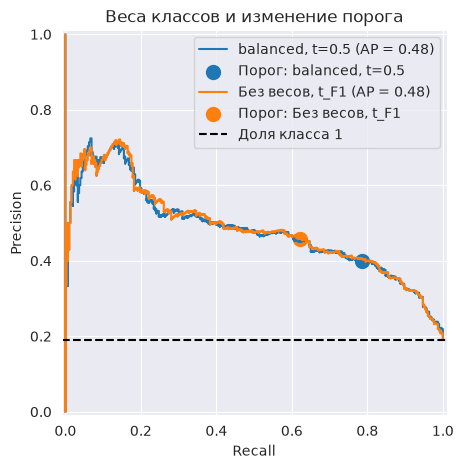

In [19]:
p_balanced = np.asarray(models_part3["balanced"].predict_proba(X_test), dtype=np.float64)[:, 1]
comparison_thresholds = {
    "balanced, t=0.5": (p_balanced, 0.5),
    "Без весов, t_F1": (p_wine_refit, t_F1),
}
display(pd.DataFrame({
    name: classification_metrics(y_test, p, t)
    for name, (p, t) in comparison_thresholds.items()
}).T)

_, ax = plt.subplots(figsize=(8, 5))
for name, (p, t) in comparison_thresholds.items():
    metrics.PrecisionRecallDisplay.from_predictions(y_test, p, name=name, ax=ax)
    point = threshold_metrics(y_test, p, t)
    ax.scatter(point["Recall"], point["Precision"], s=100, label=f"Порог: {name}")

ax.axhline(float(np.mean(y_test)), color="black", linestyle="--", label="Доля класса 1")
ax.set(title="Веса классов и изменение порога", xlabel="Recall", ylabel="Precision")
ax.legend()
plt.show()

PR-кривые близки: PR-AUC равна 0.4811 у balanced и 0.4848 без весов.

Выбранные точки различаются: recall 0.785 против 0.620, precision 0.399 против 0.457.

Взвешивание в основном напоминает снижение порога, но эквивалентность приближённая: оно меняет функцию потерь и коэффициенты, а изменение порога сохраняет ранжирование.


### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [20]:
all_results = {
    "Константа 0": classification_metrics(y_test, np.zeros(len(y_test))),
    "Рукописный GD": classification_metrics(
        y_test, wine_gd.predict_proba(X_test_wine_scaled)[:, 1]
    ),
    **results_part3,
    "Без весов, t_F1": classification_metrics(y_test, p_wine_refit, t_F1),
    "Без весов, t_R": classification_metrics(y_test, p_wine_refit, t_R),
    "NearMiss -> Scaler": order_results["NearMiss -> Scaler"],
}
summary_table = pd.DataFrame(all_results).T
summary_table.insert(0, "Порог", [
    t_F1 if name == "Без весов, t_F1" else t_R if name == "Без весов, t_R" else 0.5
    for name in summary_table.index
])
display(summary_table)

final_model = wine_model_refit
final_threshold = t_R

,Порог,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Константа 0,0.500000,0.810150,0.000000,0.000000,0.000000,0.500000,0.189850
Рукописный GD,0.500000,0.814536,0.520000,0.300330,0.380753,0.820562,0.483769
Без весов,0.500000,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
balanced,0.500000,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
RandomUnderSampler,0.500000,0.733083,0.395939,0.772277,0.523490,0.820628,0.479891
NearMiss,0.500000,0.646617,0.329412,0.831683,0.471910,0.786523,0.447903
RandomOverSampler,0.500000,0.733083,0.398010,0.792079,0.529801,0.821108,0.481077
SMOTE,0.500000,0.734962,0.397611,0.768977,0.524184,0.819595,0.479606
"Без весов, t_F1",0.286550,0.788221,0.457421,0.620462,0.526611,0.820876,0.484766
"Без весов, t_R",0.236359,0.760025,0.421260,0.706271,0.527744,0.820876,0.484766


Предлагаю регрессию без весов с $t_R\approx0.2364$, выбранным по валидации.

На тесте recall=0.7063, precision=0.4213, F1=0.5277: выполнен ориентир охвата 70%.

Precision выше, чем у сравниваемых вариантов балансировки с recall хотя бы 0.7. PR-AUC=0.4848 - наибольшая среди рассмотренных моделей. Это компромисс между охватом и ошибочными рекомендациями; гарантии recall на новых данных, разумеется, нет.


### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [21]:
import json
import joblib
from pathlib import Path

app_dir = Path("wine_app")
app_dir.mkdir(exist_ok=True)
joblib.dump(final_model, app_dir / "model.joblib")
(app_dir / "config.json").write_text(json.dumps({"threshold": float(final_threshold)}))
X_test.assign(target=y_test).to_csv(app_dir / "test.csv", index=False)

## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider("Порог", 0.0, 1.0, 0.5)
st.write("Вы выбрали порог", t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷

https://github.com/om3lette/hse-ml/tree/hw-3

https://wine-predictor-axej4y2f4yjhucg9ww4zbp.streamlit.app/